# Topic analysis of state AI legislation

**Question.** Which policy themes recur across state AI bills, how do they differ across states and over time, and do bills in different domains share the same safeguards?

**Approach.** NMF uses TF-IDF features and LDA uses word counts from each bill's NCSL summary. The overview compares eight-topic models; the later sections examine other topic counts. States, dates and outcomes are not model inputs; they are used afterwards to describe the topics.

**Run.** `python -m pip install -r requirements.txt`, then `python src/prepare.py`, then run all cells. Tables and figures are saved to `outputs/topic_analysis/`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from threadpoolctl import threadpool_limits

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(root))  # so the notebook can import src/topic_analysis.py

from src.topic_analysis import (
    TEXT, LEGAL_STOPWORDS, load_common, dominant_topics, check_topic_identity, fit_model,
    leading_word_chart, heatmap, group_share_tables, run_experiments, k_selection, recommend_k,
    k_selection_chart, new_topics_versus, case_evidence, distinct_solutions, pair_stability,
    outcome_by_topic, outcome_chart, bill_families,
)

OUT = root / "outputs/topic_analysis"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", None)

## 1. Data

The input is the shared table from `src/prepare.py`. Four bills whose full text repeats a later record were already removed there.

In [2]:
work, _ = load_common(root)  # also checks every value against the raw file

words = work[TEXT].str.split().str.len()
print(f"{len(work):,} bills from {work.Jurisdiction.nunique()} jurisdictions")
print(f"Summary length: median {words.median():.0f} words")

work[["Jurisdiction", "Bill_Number", TEXT]].head(3)

2,567 bills from 51 jurisdictions
Summary length: median 32 words


,Jurisdiction,Bill_Number,NCSL_Summary_clean
0,Alabama,H 208,"Relates to secretary of Information Technology, duties cybertechnology technology quality assurance for state agencies further provided."
1,Alabama,H 365,"Relates to state Science, Technology, Engineering, and Mathematics Council created in the Department of Workforce, membership and duties provided."
2,Alabama,H 515,Relates to AI; regulate use in health coverage decisions.


## 2. Topic model

**Why summaries rather than full text.** Cleaned full texts have a median of about 1,000 words (roughly 400 to 3,200 between the 10th and 90th percentiles), so long bills and legal boilerplate would dominate the topics. For 37% of records the stored version date differs from the introduction date, so the stored text may be an amended version. NCSL summaries are short and written in one consistent format. Full text is still used to check the eight cases in section 5.

**Settings.** English stopwords, unigrams and bigrams, `min_df=3`, `max_df=0.85`; NMF with eight topics, NNDSVDa initialization, seed 42.

**Four extra stopwords.** About a quarter of summaries open with the formula "Relates to ...", and the plain model spends a whole topic on it. Dropping `relates`, `provides`, `act` and `section` removes it. This refined model is used throughout; the plain one is compared in section 4.

In [3]:
stop_words = sorted(set(ENGLISH_STOP_WORDS) | LEGAL_STOPWORDS.keys())
vectorizer = TfidfVectorizer(stop_words=stop_words, ngram_range=(1, 2), min_df=3, max_df=0.85)
X = vectorizer.fit_transform(work[TEXT])

nmf = NMF(n_components=8, init="nndsvda", random_state=42, max_iter=500)
with threadpool_limits(limits=2):
    W = nmf.fit_transform(X)  # one row of topic weights per bill

print("Bills x terms:", X.shape)

Bills x terms: (2567, 6168)


In [4]:
# Topic names were written after reading each topic's top words and its five highest-weight summaries.
labels = json.loads((root / "notebooks/topic_labels.json").read_text(encoding="utf-8"))
names = [topic["name"] for topic in labels]

# Stop if any topic's top words differ from the ones the names were written for.
check_topic_identity(dict(model=nmf, vectorizer=vectorizer), labels)

terms = vectorizer.get_feature_names_out()
topics = dominant_topics(W)  # strongest topic per bill; -1 if the summary has no terms left

pd.DataFrame({
    "topic": range(8),
    "name": names,
    "bills": [(topics == t).sum() for t in range(8)],
    "top words": [", ".join(terms[np.argsort(-row)[:8]]) for row in nmf.components_],
})

,topic,name,bills,top words
0,0,Generic artificial-intelligence wording (weak),319,"artificial intelligence, intelligence, artificial, use artificial, use, intelligence systems, creates, establishes"
1,1,AI and generative-AI wording (weak),352,"ai, use ai, use, generative, generative ai, ai systems, requires, systems"
2,2,Synthetic media in political communications,213,"media, synthetic, synthetic media, election, deceptive, political, use synthetic, communications"
3,3,"State administration, education and study bodies (broad)",515,"state, task, task force, force, education, department, requires, technology"
4,4,Automated decisions across application domains,166,"decision, automated, employment, automated decision, use automated, systems, making, tools"
5,5,Sexual exploitation and intimate imagery,412,"sexual, child, person, image, images, material, intimate, minor"
6,6,Health services and coverage,232,"health, care, health care, insurance, services, mental, mental health, health insurance"
7,7,Algorithmic pricing and consumer restrictions,357,"prohibits, algorithmic, consumer, pricing, residential, price, certain, prohibits use"


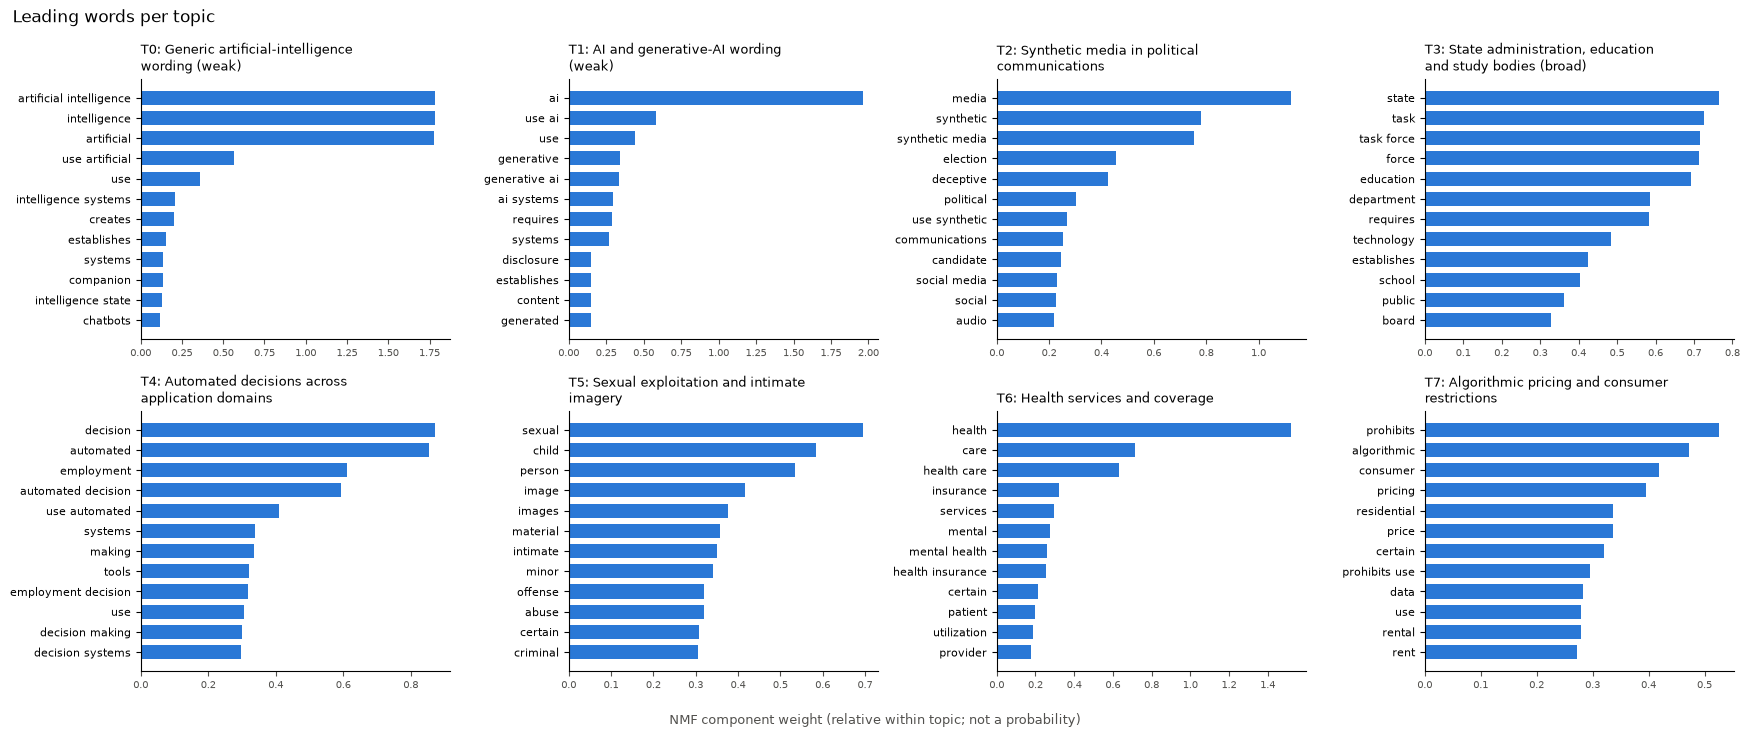

In [5]:
leading_word_chart(nmf, vectorizer, names, "Leading words per topic", OUT / "refined_leading_words.png")
plt.show()

T0 and T1 collect generic AI wording rather than a policy area. One summary (Illinois HR 142) has no terms left after filtering and stays unassigned.

## 3. Where the topics appear

Each bill's topic weights are turned into shares that sum to 1, then averaged by state and by introduction year. Shares describe the bills in this dataset, not how much a state cares about a policy.

In [6]:
group_tables = group_share_tables(work, W, OUT, "refined")  # mean shares; also saved as CSV
state_means, state_counts = group_tables["state"]
year_means, year_counts = group_tables["cohort"]

topic_columns = {t: f"T{t}: {name}" for t, name in enumerate(names)}

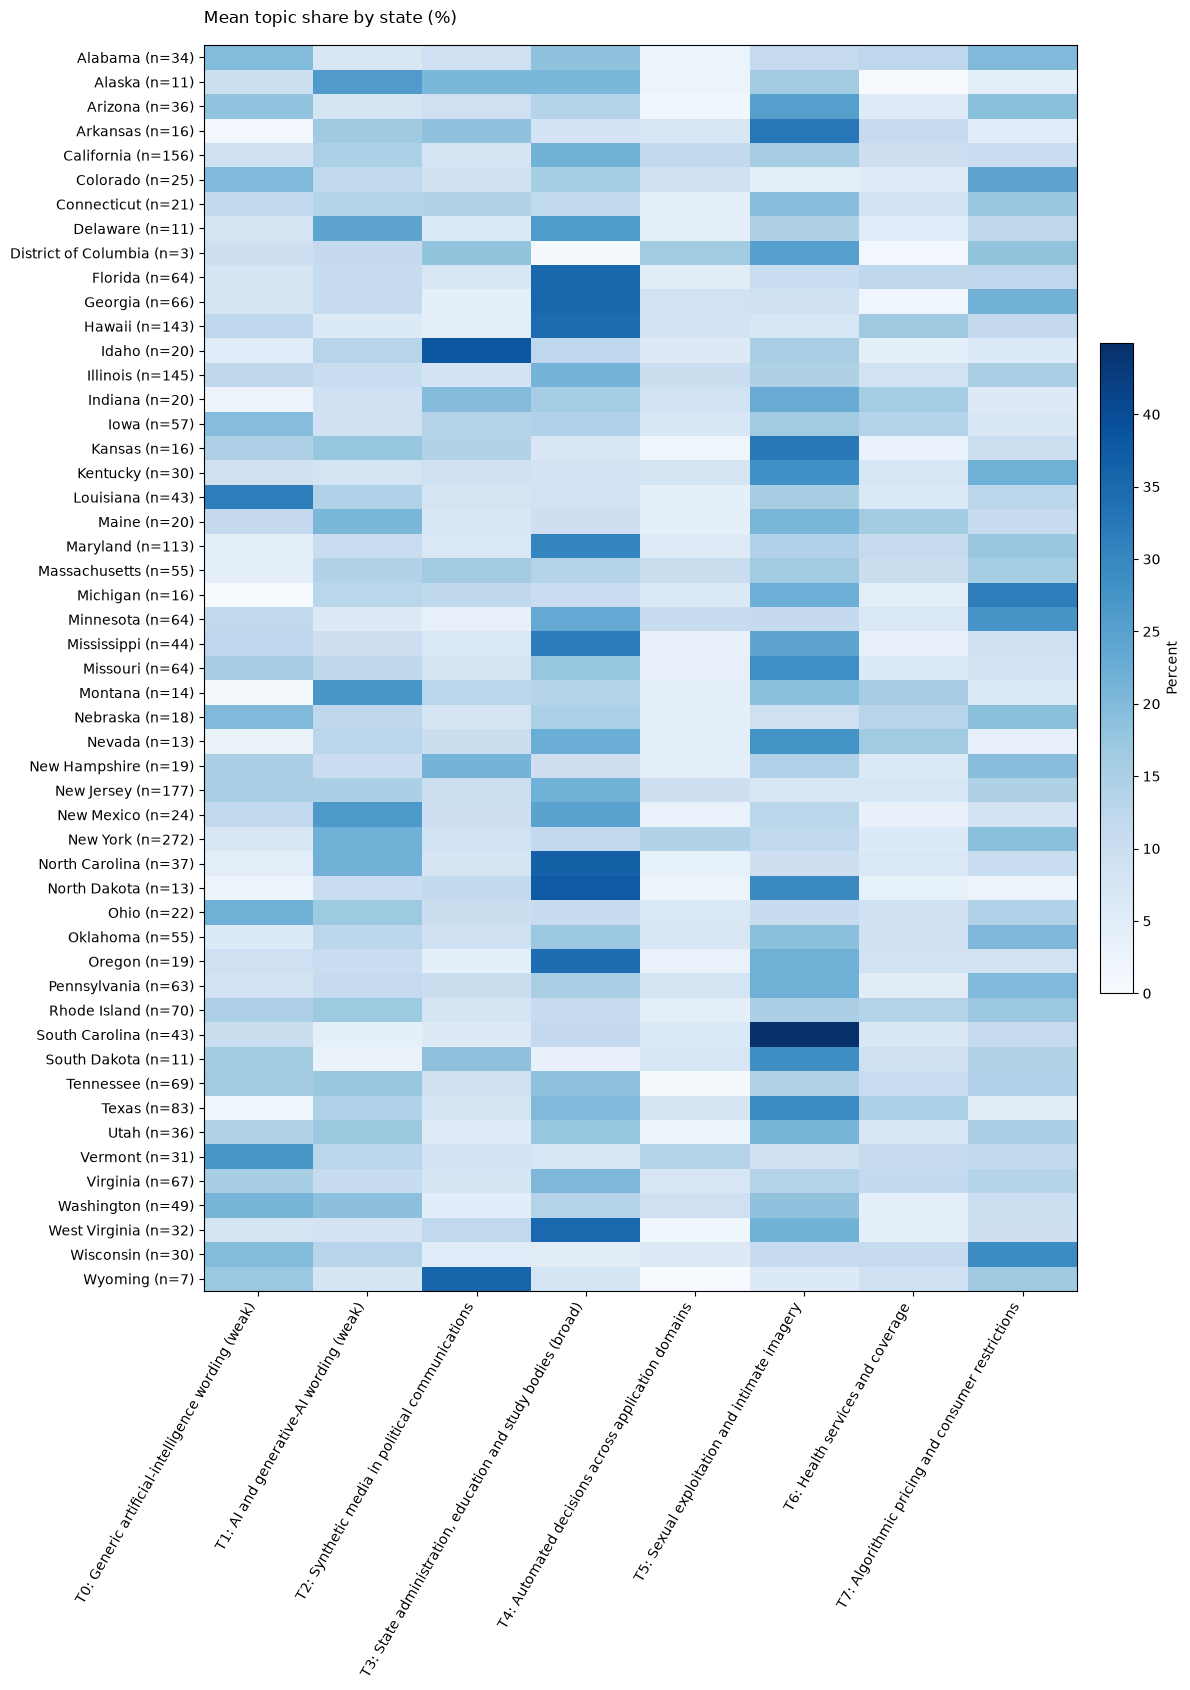

In [7]:
state_rows = {state: f"{state} (n={n})" for state, n in state_counts.records.items()}

heatmap(state_means.rename(index=state_rows, columns=topic_columns),
        "Mean topic share by state (%)", OUT / "refined_state_mean_topic_shares.png",
        percent=True, size=(12, 17), vmax=100 * state_means.to_numpy().max())
plt.show()

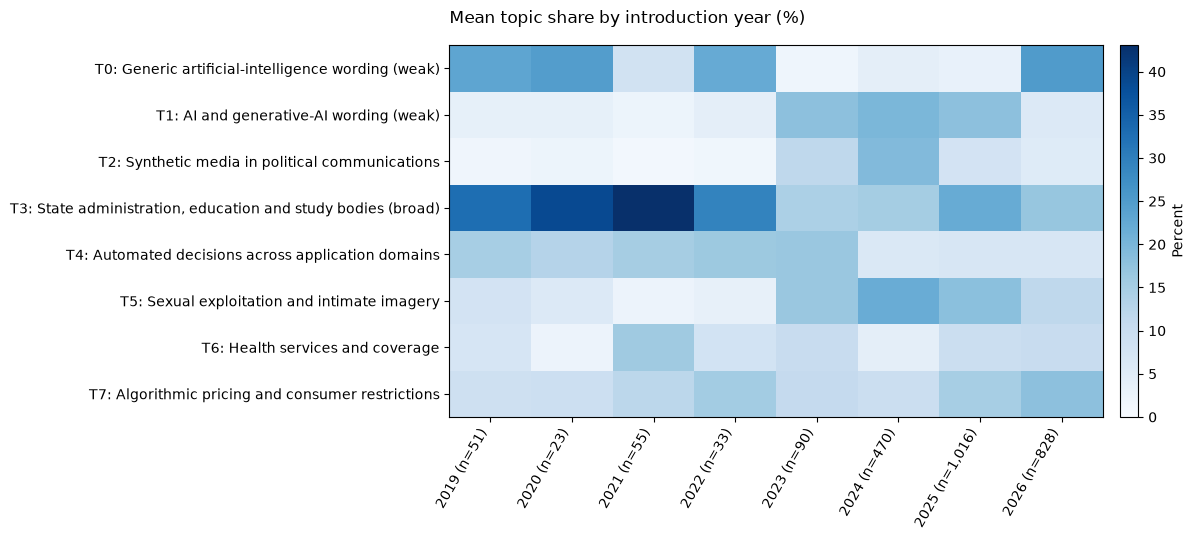

Latest introduction date: 2026-04-02 (2026 is a partial year)


In [8]:
year_means = year_means.loc[year_counts.records >= 5]  # 2018 has a single bill
year_columns = {year: f"{year} (n={n:,})" for year, n in year_counts.records.items()}

heatmap(year_means.T.rename(index=topic_columns, columns=year_columns),
        "Mean topic share by introduction year (%)", OUT / "refined_cohort_mean_topic_shares.png",
        percent=True, size=(12, 5.5), vmax=100 * year_means.to_numpy().max())
plt.show()

print("Latest introduction date:", work.introduction_date_iso.max(), "(2026 is a partial year)")

## 4. Model choice

**NMF versus LDA, and the four extra stopwords.** The first table compares eight-topic models using coherence (NPMI of the top 12 words; higher is better), term diversity (share of distinct words across topics; higher is better) and topic overlap (lower is better). The second table compares all four tested LDA counts. These are descriptive measures on the fitted corpus, not held-out performance scores.

In [9]:
baseline_vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3, max_df=0.85)
baseline_X = baseline_vectorizer.fit_transform(work[TEXT])

baseline_nmf = NMF(n_components=8, init="nndsvda", random_state=42, max_iter=500)
with threadpool_limits(limits=2):
    baseline_W = baseline_nmf.fit_transform(baseline_X)

baseline = dict(vectorizer=baseline_vectorizer, X=baseline_X, model=baseline_nmf, W=baseline_W)

# Also fits LDA, the refined and geography variants, other topic counts and other seeds.
bundles, comparison, _, _ = run_experiments(work, baseline, OUT)

main_runs = comparison.query("topics == 8 and seed == 42 and initialization != 'random'")
display(main_runs[["method", "variant", "document_npmi_top12", "top12_term_diversity", "mean_top12_jaccard"]].round(3))

lda_counts = comparison.loc[comparison.method.eq("LDA"), [
    "topics", "document_npmi_top12", "top12_term_diversity", "mean_top12_jaccard"
]]
display(lda_counts.set_index("topics").round(3))

,method,variant,document_npmi_top12,top12_term_diversity,mean_top12_jaccard
2,NMF,baseline,0.160,0.885,0.024
13,NMF,legal,0.211,0.896,0.026
14,NMF,geography,0.160,0.875,0.027
15,NMF,legal_geography,0.237,0.906,0.022
17,LDA,baseline,0.090,0.594,0.143


,document_npmi_top12,top12_term_diversity,mean_top12_jaccard
topics,,,
5,0.066,0.583,0.206
8,0.090,0.594,0.143
10,0.104,0.575,0.124
12,0.094,0.590,0.117


### LDA: leading words and state comparisons

These figures show the eight-topic LDA model. The labels use LDA's own leading words, not the NMF topic names. This model uses the full corpus for description. For classification, fit the vocabulary and topics within each training split instead of using these weights.


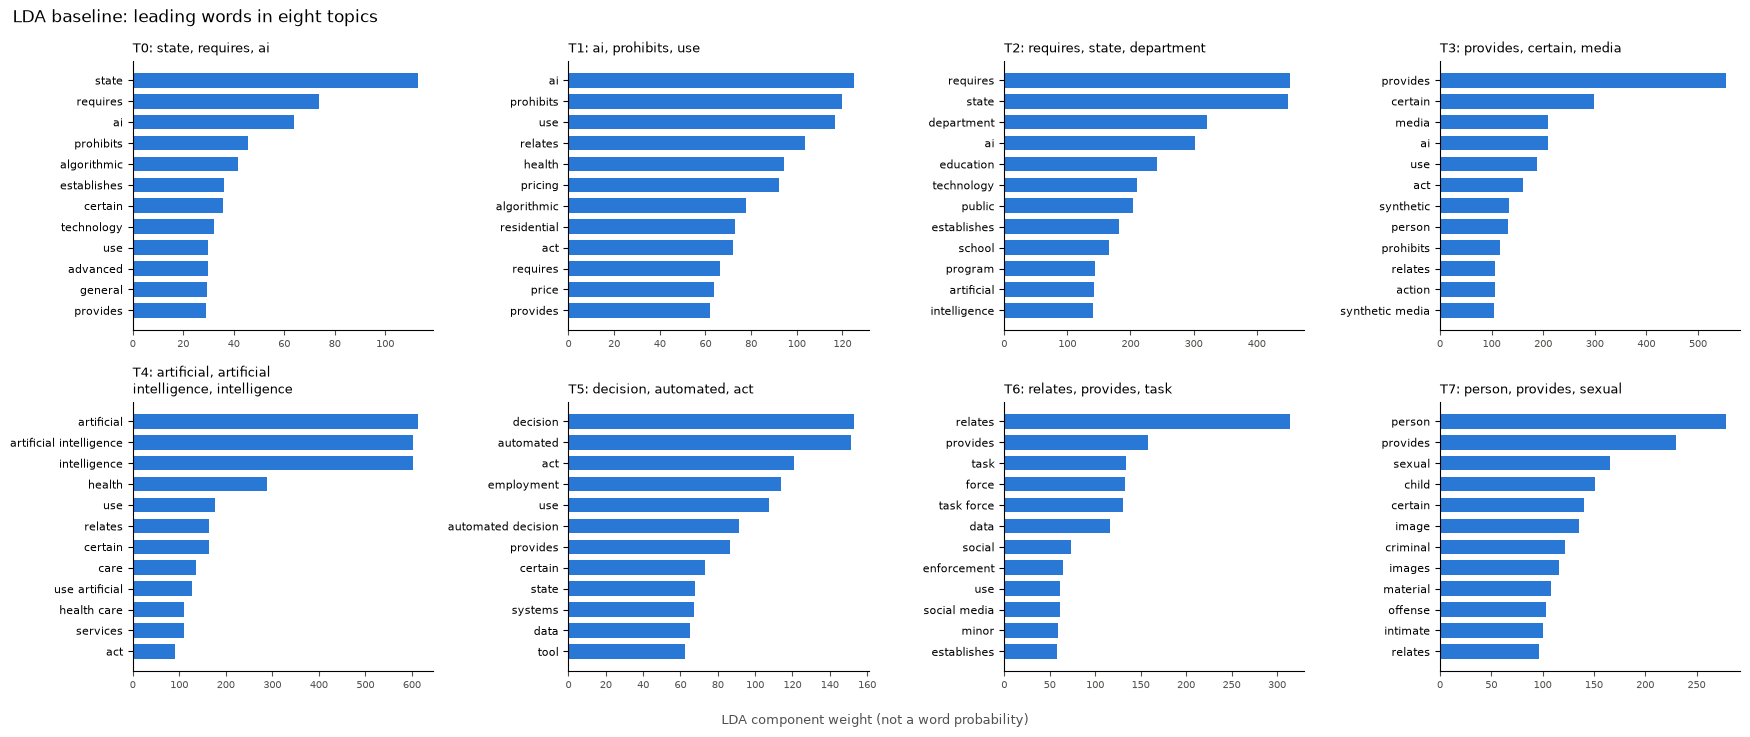

In [10]:
lda = bundles["lda_baseline_k8_seed42_batch"]
lda_terms = lda["vectorizer"].get_feature_names_out()
lda_names = [", ".join(lda_terms[np.argsort(-row)[:3]])
             for row in lda["model"].components_]
leading_word_chart(
    lda["model"], lda["vectorizer"], lda_names,
    "LDA baseline: leading words in eight topics", OUT / "lda_leading_words.png",
    weight_label="LDA component weight (not a word probability)",
)
plt.show()

The chart shows average topic weights for the 15 states with the most records. Rows list total and assigned records; averages exclude records with no usable terms. The weights are not percentages of bills assigned to a topic. The exported table includes all states.


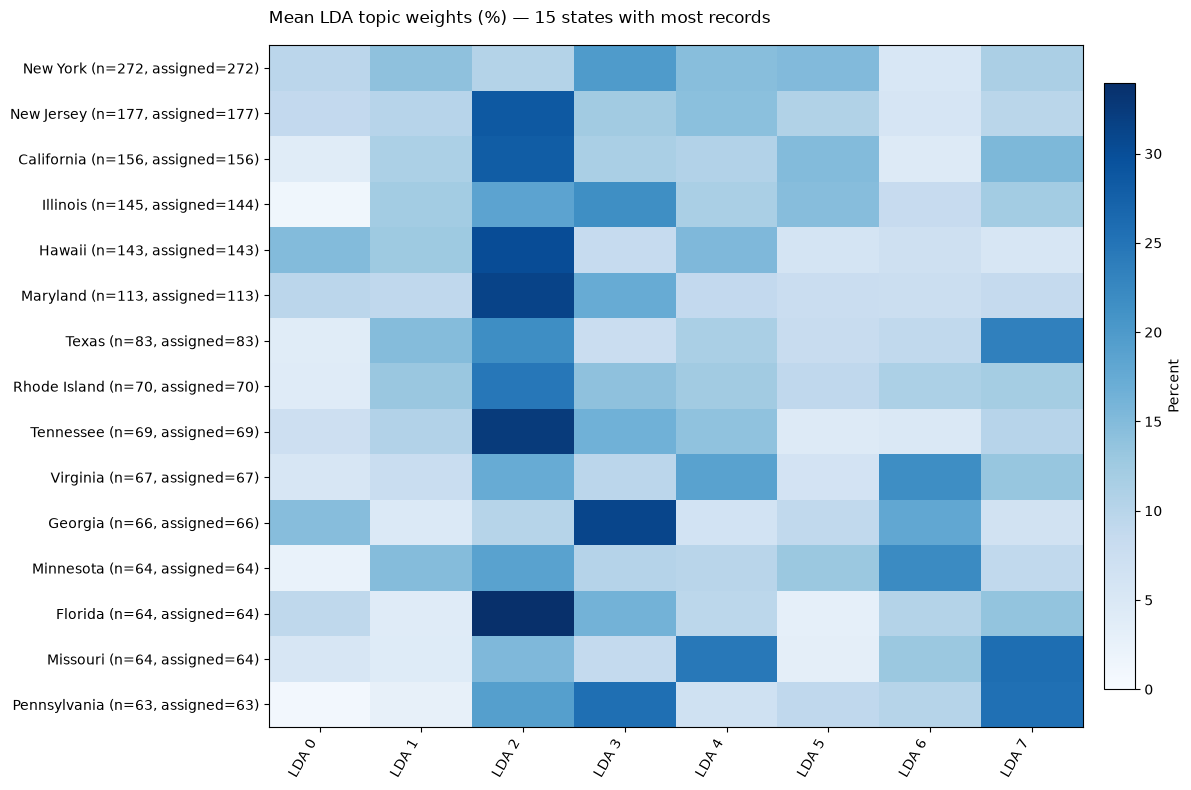

In [11]:
lda_groups = group_share_tables(work, lda["W"], OUT, "lda_baseline")
lda_state_means, lda_state_counts = lda_groups["state"]
largest_states = lda_state_counts.sort_values("records", ascending=False).head(15).index
lda_state_labels = {
    state: f"{state} (n={row.records}, assigned={row.assigned_records})"
    for state, row in lda_state_counts.iterrows()
}
heatmap(
    lda_state_means.loc[largest_states].rename(
        index=lda_state_labels, columns=lambda topic: f"LDA {topic}"
    ),
    "Mean LDA topic weights (%) — 15 states with most records",
    OUT / "lda_state_mean_topic_weights.png", percent=True, size=(12, 8),
    vmax=100 * lda_state_means.loc[largest_states].to_numpy().max(),
)
plt.show()

### LDA: review of five summaries per topic

We reviewed the five highest-weight summaries for each topic, matching the number used to name the NMF topics. These summaries are not a random sample and are not limited to bills assigned to that topic.

The review uses the summaries, state, bill number and source row to identify each example. It does not review full bill text or validate topic names. The table counts distinct summaries; the written review also notes similar wording.

In [12]:
lda_run = "lda_baseline_k8_seed42_batch"
lda_representatives = pd.read_csv(OUT / "all_run_representatives.csv")
lda_representatives = lda_representatives.loc[
    lda_representatives.run_id.eq(lda_run)
].sort_values(["topic_id", "rank"])
lda_topic_words = pd.read_csv(OUT / "all_run_topics.csv")
lda_topic_words = lda_topic_words.loc[lda_topic_words.run_id.eq(lda_run)]

# Interpretations come from reading all five exported summaries in each topic.
lda_summary_notes = {
    0: "Hawaii's algorithmic nondiscrimination, notice and reporting bills sit beside Florida's human review of insurance denials and New York's chief AI officer. Broad governance and decision mix; the Hawaii summaries are near-identical.",
    1: "Illinois price/wage surveillance and pricing disclosure sit beside Maryland reimbursement downcoding. Pricing and health are mixed; the disclosure pair is identical and the downcoding pair is near-identical.",
    2: "All five concern education technology or AI policy, curricula, evaluation or oversight, agreeing with the education words. The Hawaii curriculum summaries are identical; the other states describe different education duties.",
    3: "Illinois digital-forgery civil actions contrast with Oklahoma currency, digital-ID and medical-rights provisions. Each group has near-identical summaries; the media words do not describe the Oklahoma examples well.",
    4: "Health AI review, disclosure and consent coexist with near-identical Illinois AI product-liability summaries. The Nevada summary also repeats health-care communication wording within one record. Broad AI wording joins different policies.",
    5: "Insurance discrimination and data use, credit/hiring analytics, and impact-assessment and notice duties broadly match automated decisions. The New York insurance summaries are near-identical; employment is only part of this set.",
    6: "Workforce and education study bodies agree with the task-force words, but South Carolina's minor-exploitation summary diverges. The Illinois Future of Work pair is near-identical, and generic 'provides' and 'relates' wording recurs.",
    7: "Mississippi image/audio criminalization sits beside Illinois election-ad disclosure and deceptive-media restrictions. The Mississippi summaries repeat closely; sexual/child words do not describe all five examples.",
}

lda_review = lda_representatives.groupby("topic_id").agg(
    reviewed=("source_row", "size"),
    source_rows=("source_row", lambda rows: ", ".join(rows.astype(str))),
    distinct_summaries=("NCSL_Summary_clean", "nunique"),
).join(lda_topic_words.set_index("topic_id")[["keywords"]])
assert lda_review.index.tolist() == list(lda_summary_notes)
assert lda_review.reviewed.eq(5).all()
lda_review["keywords"] = lda_review.keywords.str.split(", ").str[:8].str.join(", ")
lda_review["summary_review"] = lda_review.index.map(lda_summary_notes)
lda_review[["keywords", "source_rows", "distinct_summaries", "summary_review"]].rename(
    columns={"keywords": "Leading words (top 8)", "source_rows": "Source rows (rank order)",
             "distinct_summaries": "Exact distinct summaries (of 5)",
             "summary_review": "Summary review"}
).rename_axis("LDA topic")

,Leading words (top 8),Source rows (rank order),Exact distinct summaries (of 5),Summary review
LDA topic,,,,
0,"state, requires, ai, prohibits, algorithmic, establishes, certain, technology","929, 938, 160, 100, 491",4,"Hawaii's algorithmic nondiscrimination, notice and reporting bills sit beside Florida's human review of insurance denials and New York's chief AI officer. Broad governance and decision mix; the Hawaii summaries are near-identical."
1,"ai, prohibits, use, relates, health, pricing, algorithmic, residential","222, 1974, 1984, 1832, 1845",4,Illinois price/wage surveillance and pricing disclosure sit beside Maryland reimbursement downcoding. Pricing and health are mixed; the disclosure pair is identical and the downcoding pair is near-identical.
2,"requires, state, department, ai, education, technology, public, establishes","2448, 289, 1746, 1758, 193",4,"All five concern education technology or AI policy, curricula, evaluation or oversight, agreeing with the education words. The Hawaii curriculum summaries are identical; the other states describe different education duties."
3,"provides, certain, media, ai, use, act, synthetic, person","1223, 1224, 1218, 646, 2304",5,"Illinois digital-forgery civil actions contrast with Oklahoma currency, digital-ID and medical-rights provisions. Each group has near-identical summaries; the media words do not describe the Oklahoma examples well."
4,"artificial, artificial intelligence, intelligence, health, use, relates, certain, care","2307, 400, 1981, 1819, 1817",5,"Health AI review, disclosure and consent coexist with near-identical Illinois AI product-liability summaries. The Nevada summary also repeats health-care communication wording within one record. Broad AI wording joins different policies."
5,"decision, automated, act, employment, use, automated decision, provides, certain","517, 1041, 1453, 208, 957",5,"Insurance discrimination and data use, credit/hiring analytics, and impact-assessment and notice duties broadly match automated decisions. The New York insurance summaries are near-identical; employment is only part of this set."
6,"relates, provides, task, force, task force, data, social, enforcement","1456, 1509, 1336, 353, 1459",5,"Workforce and education study bodies agree with the task-force words, but South Carolina's minor-exploitation summary diverges. The Illinois Future of Work pair is near-identical, and generic 'provides' and 'relates' wording recurs."
7,"person, provides, sexual, child, certain, image, criminal, images","354, 1269, 2074, 967, 1847",4,Mississippi image/audio criminalization sits beside Illinois election-ad disclosure and deceptive-media restrictions. The Mississippi summaries repeat closely; sexual/child words do not describe all five examples.


**What the summaries show.** Topic 2's education terms fit its examples, and topic 5 describes automated decisions across insurance, credit and employment. Other topics mix policy areas: topic 3 includes digital forgeries and broad rights provisions, while topic 6 combines study bodies and child exploitation. Insurance and media-related bills also appear in more than one topic.

**Repeated language.** Common words such as `provides`, `relates`, `act` and `certain` remain prominent. Every topic includes exact or near-identical summaries, so the five examples are not five independent descriptions. Topic 4 also includes a Nevada summary with repeated wording. These findings support using refined NMF for the main overview and LDA for comparison.

This review covers selected summaries only. It does not measure how common these issues are across all bills, test other LDA counts or establish that the NMF topics are uniquely correct.

At eight topics and with the same baseline vocabulary, NMF has higher term diversity than LDA (0.89 versus 0.59) and lower overlap (0.02 versus 0.14). LDA diversity stays below 0.60 at all four tested counts. NMF therefore supplies the main interpretation. Removing the four formula words raises the eight-topic NMF coherence from 0.16 to 0.21.

**NMF topic counts.** Each count from 5 to 12 is fit five times: one NNDSVDa start and four random starts. The quantitative rule selects the most stable count among those within 0.01 of the best mean NPMI. Stability measures how closely topics match across starts; it does not measure prediction accuracy.

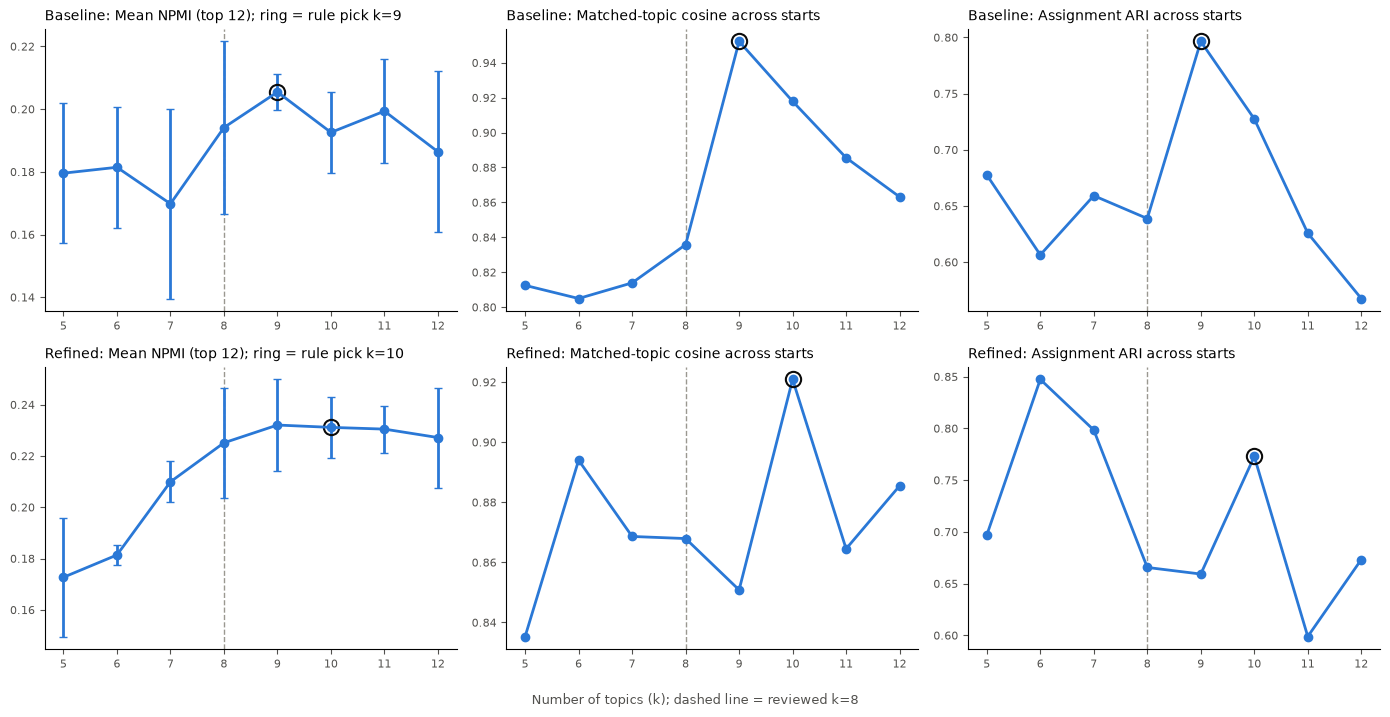

Rule picks: {'Baseline': 9, 'Refined': 10}


In [13]:
k_tables = {
    "Baseline": k_selection(work, OUT, "baseline"),
    "Refined": k_selection(work, OUT, "legal", prefix="refined"),
}
k_picks = {name: recommend_k(table) for name, table in k_tables.items()}

k_selection_chart(k_tables, 8, OUT / "k_selection.png")
plt.show()

print("Rule picks:", k_picks)

In [14]:
# Topics in the rule-picked refined model that have no close match (cosine < 0.8) among the eight.
rule_model, rule_weights, _, _ = fit_model(X, "NMF", k_picks["Refined"], 42, "nndsvda")
new_topics_versus(dict(model=nmf, W=W, vectorizer=vectorizer), dict(model=rule_model, W=rule_weights, vectorizer=vectorizer))

,topic_id,dominant_records,closest_reviewed_topic,closest_cosine,top_terms
0,3,61,3,0.581604,"task, task force, force, establishes, intelligence task, creates, establishes task, recommendations, force shall, membership"
1,9,19,3,0.008192,"commends, recognizes, dr, challenge, years, congratulates, continued success, wishes, wishes continued, dedicated"


### Retained topic counts

**NMF: eight topics for the overview.** Eight topics give a smaller set of themes and are close to the best average coherence: 0.225 at eight versus 0.232 at nine. Among counts close to the best coherence, the quantitative rule selected ten because its topics were more stable across starts. The ten-topic model separates task-force and commendation bills into their own topics; eight groups task forces with government and education. We use eight for the broader overview, while recognizing ten as a useful alternative.

**LDA: eight topics for comparison.** Eight matches the size of the NMF overview and had the highest term diversity among the LDA counts tested. Ten had higher coherence and lower overlap, but split two of the selected cross-domain bill pairs. Eight preserved all eight selected pair relationships, versus six at ten and twelve topics. These cases were hand-picked, and each LDA count was fit with one seed, so this is not a general test of LDA stability.

## 5. Eight cases: shared provisions across domains

Eight bills were picked by hand from the automated-decision and study-body topics to compare domains, states and obligations. They are examples, not a random sample. Every quote is taken from the stored `Bill_Text`, and the code checks that each one appears there exactly.

- **Safeguards around automated decisions.** IN H 1421 and NY A 9601 (employment) and SC S 443 (health coverage) ban relying only on automation and require human oversight. NY S 6471-A (housing) and NY S 8115-B (lending) share notice and assessment duties but not the same right to a human appeal.
- **Study bodies with reporting duties.** IL S 2481 (workforce), UT H 168 (education) and CO S 240 (criminal justice electronic discovery) set up study and reporting bodies in different domains. This is a shared way of organizing government, not a shared safeguard.
- **Same category, different approach.** IL S 2481 and IN H 1421 are both labeled `Effect on Labor/Employment`, but one creates a study body and the other puts duties on employers. The model separates them.

In [15]:
case_spec = json.loads((root / "notebooks/topic_case_review.json").read_text(encoding="utf-8"))
cases = case_evidence(work, case_spec["cases"], bundles, OUT)  # fails if a quote is not in Bill_Text

row_of = {source_row: i for i, source_row in enumerate(work.source_row)}
cases["topic"] = [topics[row_of[source_row]] for source_row in cases.source_row]

cases[["Jurisdiction", "Bill_Number", "application_domain", "topic", "concrete_requirements"]]

,Jurisdiction,Bill_Number,application_domain,topic,concrete_requirements
0,Indiana,H 1421,Employment,4,"No exclusive automated reliance; predeployment validation, annual independent bias testing with public results, experienced human corroboration, disclosure, and human dispute/appeal channels."
1,New York,A 9601,Employment,4,"Meaningful human evaluation before final/adverse decisions, override authority, notice of automated use and data types, and human review on an unsuccessful applicant's request."
2,South Carolina,S 443,Health coverage,4,No coverage action based solely on AI/tool results; professional supervision and meaningful review when automated tools inform modification or denial of authorization.
3,New York,S 6471,Housing applicant screening,4,"Annual disparate-impact analysis by an independent auditor; public analysis summary; notice about use, characteristics and data; denial reasons; at least 24-hour prior notice enabling an alternative selection process or accommodation request."
4,New York,S 8115,Lending,4,"At least annual impact assessments signed by responsible human reviewers, assessments before material changes, public final reports, notice, and a 30-day correction/appeal route for denials based on incorrect personal information."
5,Illinois,S 2481,Workforce and employment,3,"Assess emerging technologies and workforce effects, propose training and other policies, and submit a final report to the Governor and General Assembly."
6,Utah,H 168,Education,3,"Study and recommend education AI policies, privacy safeguards and implementation guidelines; coordinate with the AI policy office; meet at least quarterly and report annually to legislative education committees."
7,Colorado,S 240,Criminal justice electronic discovery,3,"Gather information on discovery services and access; study AI transcription availability; submit findings, recommendations and legislative proposals to budget and technology committees."


In [16]:
# Do the paired cases keep their relationship in every distinct NMF and LDA run?
# A "similar" pair should share a dominant topic; the one contrast pair should not.
distinct_bundles, _ = distinct_solutions(bundles)  # runs with the same solution count once
pair_results = pair_stability(work, distinct_bundles, case_spec["pairs"], OUT)

pair_results["method"] = pair_results.run_id.str.split("_").str[0].str.upper()
pair_results["relationship_preserved"] = np.where(
    pair_results.expected_relation.eq("similar"), pair_results.same_dominant_topic, ~pair_results.same_dominant_topic)

display(pair_results.groupby("method").agg(
    distinct_runs=("run_id", "nunique"), checks=("run_id", "size"),
    relationship_held=("relationship_preserved", "sum")))

lda_case_checks = pair_results.loc[pair_results.method.eq("LDA")].merge(
    comparison[["run_id", "topics"]], on="run_id", validate="many_to_one"
)
display(lda_case_checks.groupby("topics").agg(
    checks=("relationship_preserved", "size"),
    relationship_held=("relationship_preserved", "sum")))

,distinct_runs,checks,relationship_held
method,,,
LDA,4,32,28
NMF,12,96,96


,checks,relationship_held
topics,,
5,8,8
8,8,8
10,8,6
12,8,6


## 6. Exploratory checks (post hoc)

These two checks were added after the main review, so treat them as leads rather than tested results.

### Recorded outcomes by topic

- Only resolved bills count: Enacted and Adopted as passed, Failed and Vetoed as failed. Pending bills are left out.
- Resolutions and memorials (HR, SCR, HJM and similar) are removed.
- Each topic is compared with all others within the same introduction year and party control (Mantel–Haenszel odds ratio), so those two factors are held fixed.

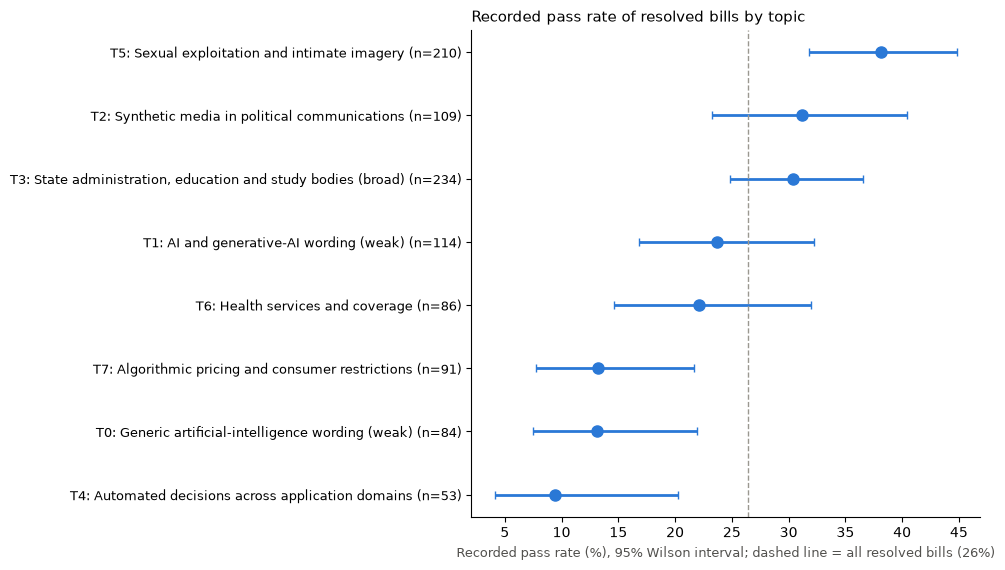

,name,resolved_bills,pass_rate,stratified_odds_ratio_vs_other_topics,cmh_p
0,Automated decisions across application domains,53,0.094,0.243,0.008
1,Generic artificial-intelligence wording (weak),84,0.131,0.589,0.194
2,Algorithmic pricing and consumer restrictions,91,0.132,0.438,0.011
3,Health services and coverage,86,0.221,0.687,0.213
4,AI and generative-AI wording (weak),114,0.237,0.695,0.159
5,"State administration, education and study bodies (broad)",234,0.303,1.352,0.108
6,Synthetic media in political communications,109,0.312,1.385,0.203
7,Sexual exploitation and intimate imagery,210,0.381,1.835,0.001


In [17]:
outcome_table, outcome_audit = outcome_by_topic(work, W, names, OUT, "refined")

outcome_chart(outcome_table, outcome_audit["overall_pass_rate"],
              "Recorded pass rate of resolved bills by topic", OUT / "refined_topic_outcomes.png")
plt.show()

outcome_table[["name", "resolved_bills", "pass_rate", "stratified_odds_ratio_vs_other_topics", "cmh_p"]].round(3)

### Text-similarity groups across states

Bills whose stored full texts have TF-IDF cosine similarity of at least 0.5
are linked into connected groups. Groups reaching four or more states are
listed. The links identify textual similarity, not proof of copying or a
common model-bill source. A connected group can also contain pairs below the
threshold because other bills connect them.


In [18]:
families, _, family_audit = bill_families(work, W, names, OUT)

print(f"{len(families)} families, {family_audit['bills_in_families']} bills")
print(f"Pass rate: family members {family_audit['family_pass_rate']:.0%} (n={family_audit['family_resolved_bills']}), "
      f"other bills {family_audit['other_pass_rate']:.0%} (n={family_audit['other_resolved_bills']})")

families[["states", "bills", "dominant_topic", "example_title", "resolved_bills", "passed"]]

11 families, 86 bills
Pass rate: family members 11% (n=28), other bills 27% (n=953)


,states,bills,dominant_topic,example_title,resolved_bills,passed
0,"Arizona, Hawaii, Iowa, Missouri, Nebraska, North Carolina, Oklahoma, Rhode Island, South Carolina",16,T2: Synthetic media in political communications,Electioneering Communications,10,0
1,"Illinois, Kentucky, New York, Ohio, Oklahoma, Rhode Island, South Carolina, Washington",11,T0: Generic artificial-intelligence wording (weak),Artificial Intelligence,1,0
2,"Illinois, Louisiana, Massachusetts, New York, Tennessee, Utah",8,T0: Generic artificial-intelligence wording (weak),Artificial Intelligence,2,1
3,"Colorado, Illinois, New York, Texas, Virginia",10,T7: Algorithmic pricing and consumer restrictions,Residential Landlord and Tenant Act,4,0
4,"California, Illinois, Oklahoma, Rhode Island, Washington",7,T4: Automated decisions across application domains,Automated Decision Tools,3,0
5,"Mississippi, New Jersey, Oklahoma, South Carolina, Tennessee",7,T5: Sexual exploitation and intimate imagery,ELVIS Act of 2025,4,1
6,"Kansas, Louisiana, Pennsylvania, Rhode Island, Vermont",6,"T3: State administration, education and study bodies (broad)",Clean Air Preservation Act,1,0
7,"Iowa, Nebraska, New York, Oklahoma, Tennessee",6,T7: Algorithmic pricing and consumer restrictions,Consumer Protection,0,0
8,"Colorado, New York, Oklahoma, Rhode Island",6,T7: Algorithmic pricing and consumer restrictions,Business Regulation Regarding Insurance Discrimination,3,1
9,"California, Iowa, Louisiana, New York",5,T4: Automated decisions across application domains,Employment: Automated Decision Systems,0,0


## 7. Key results

1. **Themes.** The bills fall into six policy topics: deepfakes in elections (T2), government, schools and study groups (T3), automated decisions (T4), sexual deepfakes and exploitation (T5), health care (T6) and pricing algorithms (T7). The other two topics (T0, T1) are just general AI wording.
2. **States.** Some states focus heavily on one topic. Among states with at least 40 bills: South Carolina has a mean normalized weight of 45% for sexual deepfakes, Florida 35% for government and schools, Minnesota 27% for pricing, Hawaii 17% for health, Massachusetts 16% for election deepfakes and New York 14% for automated decisions. These are average topic weights, not percentages of bills assigned to a topic.
3. **Over time.** Study-body and automated-decision topics have substantial weight in the earlier cohorts. Election and sexual-deepfake topic weights peak in 2024. Health-topic weight rises from 4% in 2024 to 9% in 2025 and 10% in partial-year 2026, below its 16% share in 2021. Pricing reaches its largest share in 2026 (18%).
4. **Shared provisions.** Bills from different areas (jobs, health, housing, lending) use the same kinds of safeguards, such as human review of automated decisions. The selected pair relationships hold in 96 of 96 checks across 12 distinct NMF runs, and 28 of 32 checks across four distinct LDA runs.
5. **Which bills pass.** About one in four finished bills passed (26% of 981). Sexual deepfake bills passed most often (38%) and automated-decision bills least often (9%). These gaps remain after accounting for year and which party controls the state, and only the sexual deepfake result stays significant after correcting for testing eight topics.
6. **Text-similarity groups.** 11 connected groups reach four or more states (86 bills in total). Among resolved group members, 11% passed, compared with 27% of other resolved bills. Shared wording does not establish a common author or copying.

**Interpretation.**

The summaries show changes in the relative weight of study bodies, automated
decisions, deepfakes, health and pricing across introduction years. These
descriptive comparisons do not establish why attention changed. News events,
industry opposition and legislative copying would need separate evidence.

Recorded pass rates also differ across the selected topics. The outcome checks
are exploratory associations, including stratified comparisons, rather than
evidence that a topic caused a bill to pass or fail. Text-similarity groups
provide leads for further source review, without establishing their origins.

## 8. Limits

- Summaries are short, so they can leave out who a bill applies to, its exceptions and its duties. Their fixed wording also shapes the topics.
- The eight cases are hand-picked examples, not a random sample. Their quotes come from the one version of each bill stored in the dataset, which may differ from the final law.
- Some bills are near-copies of each other (for example, House and Senate versions of the same bill), so the bills are not fully independent.
- The outcome and text-similarity checks were added after the main analysis. They show patterns, not causes.